# Borrowed windows and iterator lifetimes

Follow a feature that shapes how this language is used in practice.

Work with a small fixture so that every returned value can be checked by hand. Keep the ordering of inputs visible. Trace resource ownership, data shape or scheduling as appropriate, and identify the exact point where the result becomes available to the caller.

windows returns slices into the original allocation. The returned iterator borrows the input for its own lifetime. Each window is reduced without copying its elements.

In [1]:
from pathlib import Path
import sys, math, statistics
import numpy as np
import matplotlib.pyplot as plt

here = Path.cwd()
sys.path.insert(0, str(here.parent.parent))
from course_runner import run_native

## Native source

`native.rs`

```rust
fn means(values: &[i32], width: usize) -> impl Iterator<Item = f64> + '_ {
    assert!(width > 0);
    values.windows(width).map(|window| {
        f64::from(window.iter().sum::<i32>()) / window.len() as f64
    })
}
fn main() {
    let readings = vec![2, 4, 8, 1, 3, 7];
    for mean in means(&readings, 3) { print!("{mean} "); }
}
```

## Execute the native listing

windows returns slices into the original allocation. The returned iterator borrows the input for its own lifetime. Each window is reduced without copying its elements. Read the type and ownership information at the function boundary. A borrowed slice permits access to existing storage while the owner retains responsibility for its lifetime.

In [2]:
x = [2, 4, 8, 1, 3, 7]
expected = np.asarray([sum(x[i : i + 3]) / 3 for i in range(len(x) - 2)], dtype=float)
engine, stdout = run_native(here / "native.rs")
observed = np.asarray([float(v) for v in stdout.split()])
assert observed.shape == expected.shape
np.testing.assert_allclose(observed, expected, rtol=2e-7, atol=2e-7)
print("Runtime:", engine)
print("Native stdout:", stdout.strip())
print("Largest absolute difference:", f"{np.max(np.abs(observed-expected)):.3g}")

Runtime: Rust
Native stdout: 4.666666666666667 4.333333333333333 4 3.6666666666666665
Largest absolute difference: 0


## Read the output

The independent calculation describes the expected output. Its agreement with the native result tests both the values and their order. The marks show the independent Python reference at each position.

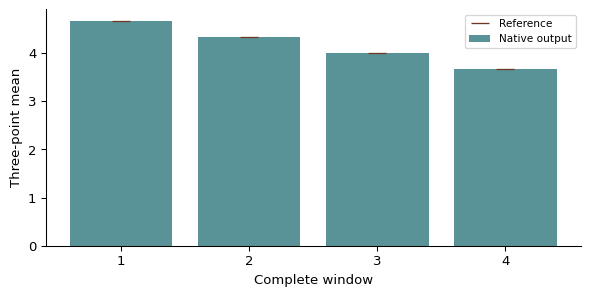

In [3]:
labels = [str(v) for v in range(1, 5)]
positions = np.arange(len(labels))
fig, ax = plt.subplots(figsize=(6.1, 3), constrained_layout=True)
ax.bar(positions, observed, color="#367b80", alpha=0.82, label="Native output")
ax.plot(
    positions,
    expected,
    linestyle="none",
    marker="_",
    markersize=13,
    color="#713925",
    label="Reference",
)
ax.set(xticks=positions, xticklabels=labels, xlabel="Complete window", ylabel="Three-point mean")
ax.legend(fontsize=8)
plt.show()

## Interpreting the result

The independent calculation describes the expected output. Its agreement with the native result tests both the values and their order.

## Exercise

Change the input length, add a repeated value and predict all output positions before running the programme.

## References

[The Rust Programming Language](https://doc.rust-lang.org/book/)